In [1]:
### Libraries - Joe
import itertools
import pandas as pd
import numpy as np
from numpy.polynomial.legendre import legvander
import sklearn as sk
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import brentq, linprog
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import math
np.random.seed(42)

### Part 1 - The VC Confidence term - Joe

In [2]:
### a - Implement fm(h) with η = 0.05 - Joe
def fm(h,m, η = 0.05):
    # sqrt( (h*a-b) / m )
    a = np.log(2*m / h)+1
    b = np.log(η/4)

    return np.sqrt( (h*a-b) / m)


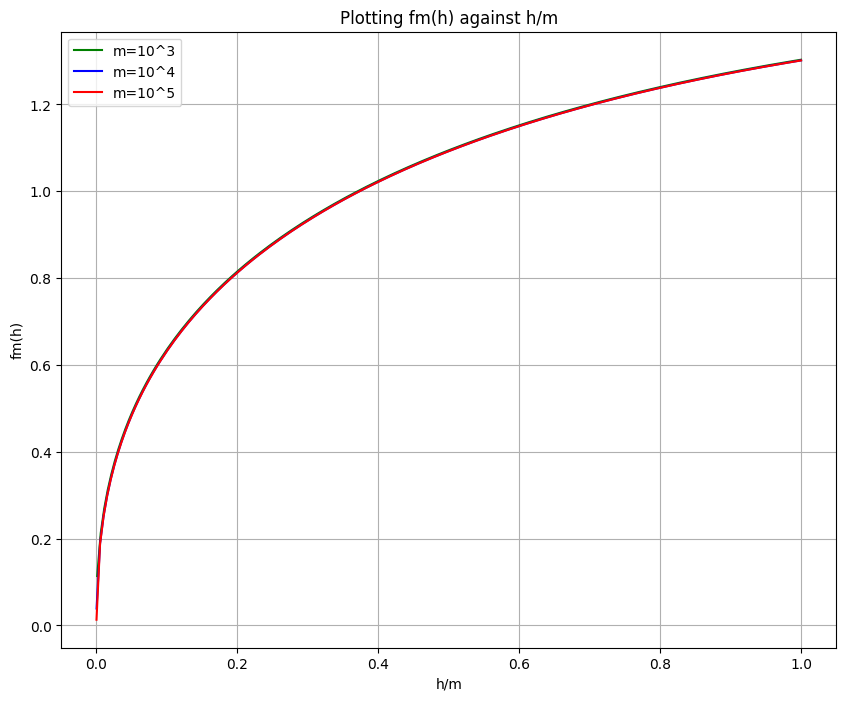

In [3]:
### a - Plot fm(h) against h/m for m \in {10^3,10^4,10^5} - Joe
ms= [10**3,10**4,10**5]
hs = [0,0,0]
for i in range(len(ms)):
    # grab values of h evenly from 1...m
    hs[i] = np.round(np.linspace(1,ms[i],200)).astype(int)
    #print(hs[i])

# plot the three curves, they will look very similar until zoomed in
fig,ax = plt.subplots(figsize=(10,8))
ax.plot(hs[0]/ms[0], fm(hs[0], ms[0]), label='m=10^3', color='g')
ax.plot(hs[1]/ms[1], fm(hs[1], ms[1]), label='m=10^4', color='b')
ax.plot(hs[2]/ms[2], fm(hs[2], ms[2]), label='m=10^5', color='r')
ax.set_xlabel('h/m')
ax.set_ylabel('fm(h)')
ax.set_title("Plotting fm(h) against h/m")
ax.grid()
ax.legend()
plt.show()


In [4]:
### b - find the ratio at which fm(h)=1 - Joe
for m in ms:
    # brentq finds func at 0, so for 1, fm -1,
    # https://pythonguides.com/python-scipy-optimize-root/
    r = brentq(lambda h: fm(h*m, m) - 1, 1/m, 1)    
    print("h/m ratio for fm(h)=1 : m={}, h/m={:.4f}".format(m, r))


h/m ratio for fm(h)=1 : m=1000, h/m=0.3708
h/m ratio for fm(h)=1 : m=10000, h/m=0.3731
h/m ratio for fm(h)=1 : m=100000, h/m=0.3733


In [5]:
### c - find largest integer VC dim h for which bound guarantees R(alpha) <= 0.1
### when Remp=0, Remp=0.05 - Joe

# we have r(a) <= remp(a) + fm(h) bounded by 0.1, remp(a) + fm(h)<=0.1
# rearrange as fm(h) <= 0.1 - remp(a)
m=10**4
remps = [0,0.05]
for remp in remps:
    # check int vals 1->m
    hs = np.arange(1,m+1)
    # list of values that satisfy the bound
    satisfies = hs[fm(hs,m) <= 0.1 - remp]

    if not len(satisfies):
        print("No h satisfies")
    else:
        print("For Remp = {}, largest h = {}".format(remp,satisfies[-1]))

For Remp = 0, largest h = 11
For Remp = 0.05, largest h = 2


### Part 2 - A shattering checker - Joe

In [6]:
### Implement can_shatter(X) - Joe
def separable(X,y):
    """Return True if labels y in {-1,+1} are linearly separable on X."""
    m, n = X.shape
    # variables z = (w_1..w_n, b); constraint -y_i (w.x_i + b) <= -1
    A_ub = -y[:, None] * np.hstack([X, np.ones((m, 1))])
    b_ub = -np.ones(m)
    res = linprog(c=np.zeros(n + 1), A_ub=A_ub, b_ub=b_ub,
    bounds=[(None, None)] * (n + 1), method="highs")
    return res.status == 0 # 0 = feasible solution found


def can_shatter(X):
    # loop over all possible labelings
    labelings = itertools.product([-1,1], repeat=len(X))
    for labels in labelings:
        y = np.array(labels)

        # if any labeling is not separable, X can not shattered
        if not separable(X,y):
            return False

    return True


In [7]:
### a - verify the three non-collinear points - Joe
x1 = np.array([[0,0],[1,0], [0,1]])
print("Non-collinear:", can_shatter(x1))

### a - verify three collinear points - Joe
x2 = np.array([[0,0],[1,0], [2,0]])
print("Collinear:", can_shatter(x2))

Non-collinear: True
Collinear: False


2
3
4
5


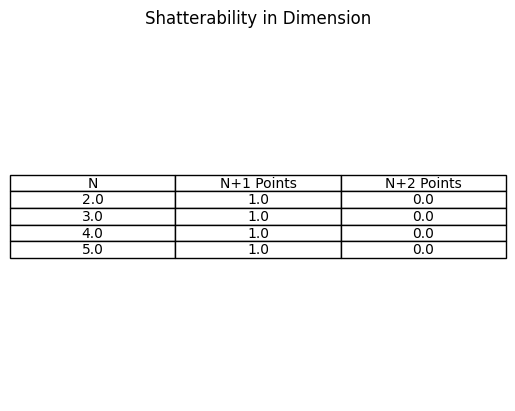

In [8]:
### b - sweep through n and sample points, report table of shattering - Joe
ns = [2,3,4,5]
fracshatter1 = []
fracshatter2 = []
for n in ns:
    print(n)
    # num shatters
    shatter1 = 0
    shatter2 = 0

    for i in range(1000):
        # sample iid standard normal# Sample iid standard normal points
        points1 = np.random.normal(size=(n+1, n))
        points2 = np.random.normal(size=(n+2, n))

        if can_shatter(points1):
            shatter1 += 1

        if can_shatter(points2):
            shatter2 += 1

    # add to lists
    fracshatter1.append(shatter1/1000)
    fracshatter2.append(shatter2/1000)

# plot table
fig,ax = plt.subplots()
ax.axis("off")
ax.set_title("Shatterability in Dimension")
table = pd.DataFrame(
    {
    "N" : ns,
    "N+1 Points": fracshatter1,
    "N+2 Points" : fracshatter2
})
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
plt.show()


Random Points (4,2): [[-0.65720213 -1.05710005]
 [ 0.0943653   0.93449729]
 [ 0.36545828 -0.3679115 ]
 [-0.30979488 -1.65667606]]
Non-separable Labelings: [array([-1,  1, -1,  1]), array([ 1, -1,  1, -1])]


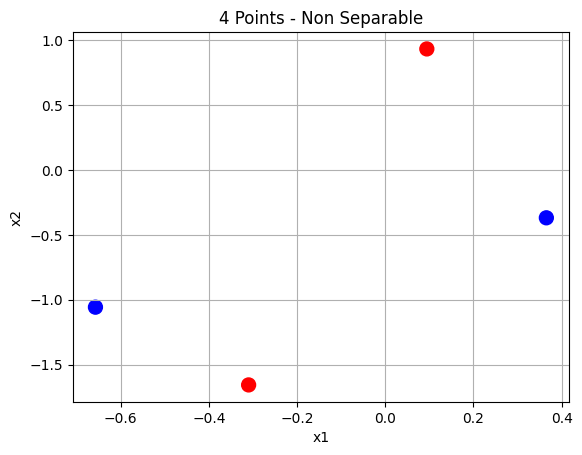

In [38]:
### c - take random set, list those not separable - Joe
ranpoints = np.random.normal(size=(4,2))
ranpointsLabels = itertools.product([-1,1], repeat=len(ranpoints))

notSep = []
# iterate through labelings and determine not separable
for labels in ranpointsLabels:
    y = np.array(labels)

    if not separable(ranpoints,y):
        notSep.append(y)

print("Random Points (4,2): {}".format(ranpoints))
print("Non-separable Labelings: {}".format(notSep))

# visualize one label that is not separable
y = notSep[0]
fig,ax = plt.subplots()
ax.scatter(
    ranpoints[:,0],
    ranpoints[:,1],
    c=y,
    cmap='bwr',
    s=100
)

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_title("4 Points - Non Separable")
ax.grid(True)
plt.show()

In [10]:
### d - write an analogous checker for axis-aligned rectangles - Joe

# essentially case one - find boundingbox - check if contains negative point
def bounding_box_check(X,y):
    #grab labels
    pos = X[y==1]
    neg = X[y==-1]

    #edge check
    if not len(pos) or not len(neg):
        return True

    #get bounding box
    mins = np.min(pos, axis=0)
    maxs = np.max(pos, axis=0)

    # check if negative exists inside bounding box
    for p in neg:
        if np.all(p >=mins) and np.all(p <= maxs):
            return False

    # none found
    return True

# new can chatter using bounding box only
def can_shatter_bounding_box(X):
    labelings = itertools.product([-1,1], repeat=len(X))
    for labels in labelings:
        y = np.array(labels)

        if not bounding_box_check(X,y):
            return False

    # separable
    return True

In [11]:
### d - check 4 points - Joe
ps = np.array([
    [-1,0],
    [1,0],
    [0,-1],
    [0,1]
])
print("Points: {}, are shattered: {}".format(ps,can_shatter_bounding_box(ps)))


Points: [[-1  0]
 [ 1  0]
 [ 0 -1]
 [ 0  1]], are shattered: True


In [12]:
### d - check 1000 5-point sets - Joe
shatter=0
for i in range(1000):
    pts = np.random.normal(size=(5,2))

    if can_shatter_bounding_box(pts):
        shatter+=1
        print("False: Set of (5,2) got shattered")
        break
if not shatter:
    print("True: None of 1000 - (5,2) sets got shattered")


True: None of 1000 - (5,2) sets got shattered


### P3 - PAC Learning in action: Rectangles and thresholds - Joe

In [13]:
### init values - Joe
P = np.array([[0, 1], [0, 1]])
print(P)
c_star = np.array([[0.2, 0.7], [0.3, 0.6]])
print(c_star)

[[0 1]
 [0 1]]
[[0.2 0.7]
 [0.3 0.6]]


In [14]:
### implement PAC leaarner for rectangle - Joe
def pac_learner(X,y):
    pos = X[y==1]

    #edge check
    if not len(pos):
        return None

    mins = np.min(pos, axis=0)
    maxs = np.max(pos, axis=0)

    # combine arrays by appending columns
    return np.column_stack((mins,maxs))

In [15]:
### helper function to compute true error - Joe
def compute_true_error(h, c_star):
    if h is None: 
        return 0.15

    width = h[0,1] - h[0,0]
    height = h[1,1] - h[1,0]

    true_err = 0.15 - width * height
    return true_err

In [16]:
### a - compute true err - Joe
sampleM = 1000
X = np.random.uniform(0,1,(sampleM,2))

# mask of points inside the rectangle, first condition checks lower bound, second checks upper bound
inside = np.all((X >= c_star[:,0]) & (X <= c_star[:,1]), axis=1)
# assigns 1 for points inside the rectangle, -1 for points outside
y = np.where(inside, 1, -1)

h = pac_learner(X,y)
true_err = compute_true_error(h, c_star)

print("True Error: {:.4f}".format(true_err))

True Error: 0.0049


In [17]:
### b - sweep m's and run 2000 independent trials, compute mean true error and error fractions - Joe
ms = [10,20,50,100,200,500,1000]
T = 2000
eps = 0.05
mtes = []
errFracs = []
for m in ms:
    tes = []
    for t in range(T):
        X = np.random.uniform(0,1,(m,2))
        inside = np.all((X >= c_star[:,0]) & (X <= c_star[:,1]), axis=1)
        y = np.where(inside, 1, -1)
        h = pac_learner(X,y)
        tes.append(compute_true_error(h, c_star))

    # append mean true error
    mtes.append(np.mean(tes))

    # compute fraction of trials with R>eps
    errFracs.append(np.mean(np.array(tes) > eps))

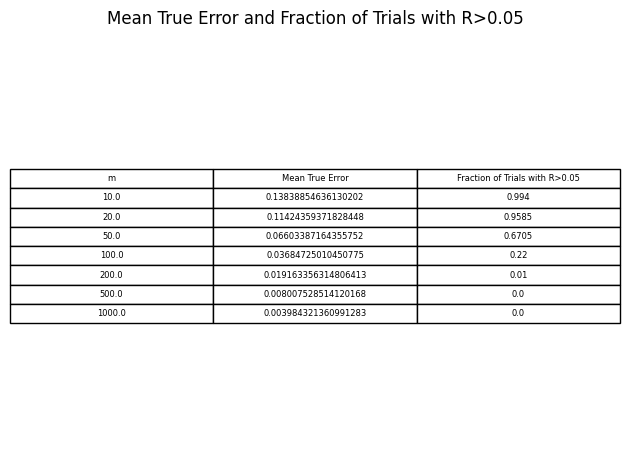

In [18]:
### b - report results - Joe
table = pd.DataFrame({
    "m" : ms,
    "Mean True Error" : mtes,
    "Fraction of Trials with R>0.05" : errFracs
})
fig,ax = plt.subplots()
ax.axis("off")
ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
plt.title("Mean True Error and Fraction of Trials with R>0.05")
plt.tight_layout()
plt.show()

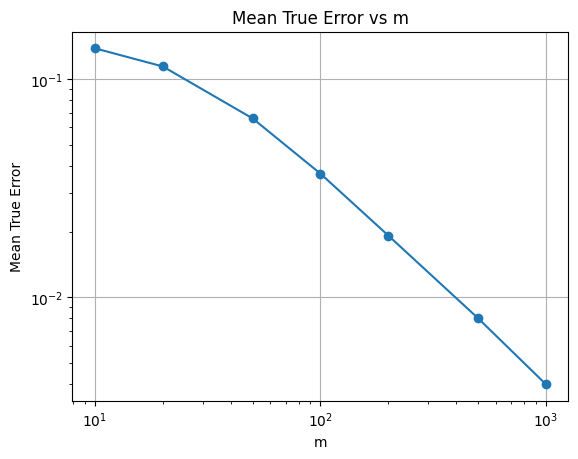

In [19]:
### c - plot mte vs m - Joe
fig,ax = plt.subplots()

# log log axes
ax.loglog(ms, mtes, marker='o', label='Mean True Error')
ax.set_xlabel('m')
ax.set_ylabel('Mean True Error')
ax.set_title('Mean True Error vs m')
ax.grid()
plt.show()

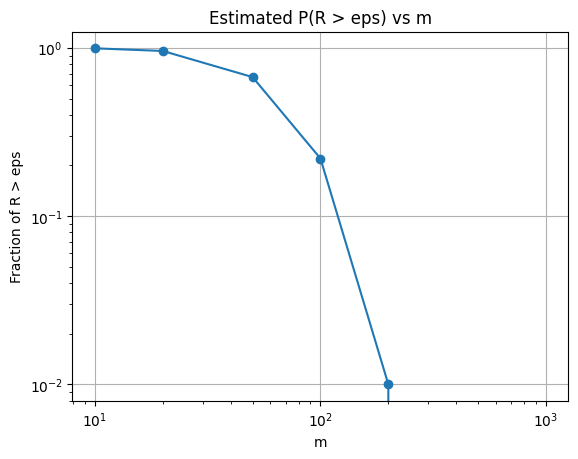

In [20]:
### c - plot mte vs m - Joe
fig,ax = plt.subplots()

# log log axes
ax.loglog(ms, errFracs, marker='o', label='Fraction of R > eps')
ax.set_xlabel('m')
ax.set_ylabel('Fraction of R > eps')
ax.set_title('Estimated P(R > eps) vs m')
ax.grid()
plt.show()

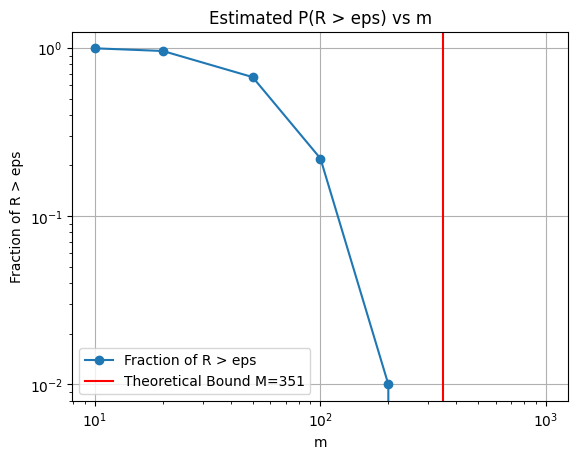

In [21]:
### c - mark plot with theoretical m - Joe
fig,ax = plt.subplots()

# log log axes
ax.loglog(ms, errFracs, marker='o', label='Fraction of R > eps')
# mark theoretical m
ax.axvline(x=351,color='red' ,label='Theoretical Bound M=351')
ax.set_xlabel('m')
ax.set_ylabel('Fraction of R > eps')
ax.set_title('Estimated P(R > eps) vs m')
ax.grid()
ax.legend()
plt.show()

In [22]:
### c - find smallest m (to nearest 10) - Joe
delta = 0.05
probs = []
find_ms = []
# theoretical is 351
for m in range(10,360,10):
    errs = []
    for t in range(T):
        X = np.random.uniform(0,1,(m,2))
        inside = np.all((X >= c_star[:,0]) & (X <= c_star[:,1]), axis=1)
        y = np.where(inside, 1, -1)
        h = pac_learner(X,y)
        errs.append(compute_true_error(h, c_star))
    find_ms.append(m)
    probs.append(np.mean(np.array(errs) > eps))

lowestM = 360
empM = float('inf')
for m,prob in zip(find_ms,probs):
    if prob <= delta:
        lowestM = m
        empM = prob
        break

print("Lowest M - to 10s : {}".format(lowestM))
print("Empirical Probability: {:.5f}".format(empM))
print("Pessimistic Factor: {:.5f}".format(351/lowestM))

Lowest M - to 10s : 150
Empirical Probability: 0.03300
Pessimistic Factor: 2.34000


In [23]:
### d - fit straight line of mean vs err = Joe
slope,intercept = np.polyfit(np.log(ms), np.log(mtes),1)

B = -slope
print("Beta : {:.4f}".format(B))

fit = np.exp(intercept)*np.array(ms)**slope


Beta : 0.7945


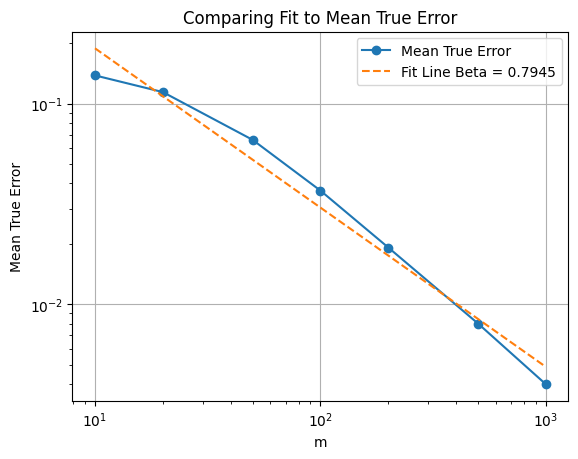

In [24]:
### d - plot fit - Joe
fig,ax = plt.subplots()
ax.loglog(ms,mtes, marker='o', label="Mean True Error")
ax.loglog(ms, fit, '--', label="Fit Line Beta = {:.4f}".format(B))
ax.set_xlabel('m')
ax.set_ylabel('Mean True Error')
ax.legend()
ax.grid()
ax.set_title("Comparing Fit to Mean True Error")
plt.show()


### P4 - Structural Risk Minimization vs Cross-validation - Joe

In [25]:
### helper function to generate splits
def train_test_split(m):
    # generate data and labels
    X = np.random.uniform(-1,1,m)
    y = np.where(np.sin(3*np.pi*X) >=0,1,-1)

    # flip with prob 0.1
    flips = np.random.rand(m) < 0.1
    y[flips] = -y[flips]
    return X,y
# m =200 training, 10^4 test points
m = 200
T = 10000
x_tr, y_tr = train_test_split(m)
x_te, y_te = train_test_split(T)


In [26]:
### b - fit h_d classifier using given helper code for SVM - Joe
trainErrs = []
testErrs = []
vcBounds = []
eta = 0.05

for d in range(1,16):
    def features(x, d):
        return legvander(x, d)[:, 1:] # columns P_1(x)..P_d(x); constant dropped
    clf = LinearSVC(C=1e4, max_iter=200000).fit(features(x_tr, d), y_tr)

    # train err
    p_train = clf.decision_function(features(x_tr, d)) # this is the learned p(x)
    y_hat_train = np.where(p_train > 0, 1, -1) # sign(p(x))
    trainErr = np.mean(y_hat_train != y_tr)
    trainErrs.append(trainErr)

    # test err
    p_test = clf.decision_function(features(x_te, d)) # this is the learned p(x)
    y_hat = np.where(p_test > 0, 1, -1) # sign(p(x))
    testErr = np.mean(y_hat != y_te)
    testErrs.append(testErr)

    # vc bound
    vc = d+1
    vcBound = trainErr + fm(vc, m, eta)
    vcBounds.append(vcBound)

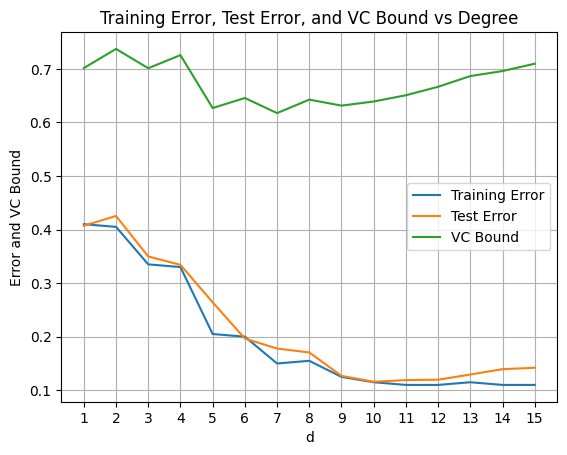

In [27]:
### c - display results - Joe
fig, ax = plt.subplots()

ax.plot(list(range(1,16)), trainErrs, label='Training Error')
ax.plot(list(range(1,16)), testErrs, label='Test Error')
ax.plot(list(range(1,16)), vcBounds, label='VC Bound')

ax.set_xlabel('d')
ax.set_ylabel('Error and VC Bound')
ax.set_title('Training Error, Test Error, and VC Bound vs Degree')
ax.set_xticks(list(range(1,16)))
ax.legend()
ax.grid(True)

plt.show()

In [28]:
### c - finding which degree SRM selects - Joe
ds = np.array(list(range(1,16)))
dSRM = ds[np.argmin(vcBounds)]
print("Degree selected by SRM: {}".format(dSRM))

Degree selected by SRM: 7


In [29]:
### c - finding which degree 5-fold cross validation selects - Joe
errs = []

for d in range(1,16):
    def features(x, d):
        return legvander(x, d)[:, 1:]
    clf = LinearSVC(C=1e4, max_iter=200000)

    # 5fold cross validation
    scores = cross_val_score(clf, features(x_tr, d), y_tr, cv=5)
    # convert to mean error
    mean_err = 1 - np.mean(scores) 
    errs.append(mean_err)
dCV = ds[np.argmin(errs)]
print("Degree selected by 5-fold CV: {}".format(dCV))

Degree selected by 5-fold CV: 9


In [30]:
### c - find which minimizes test error- Joe
dMinT = ds[np.argmin(testErrs)]
print("Degree selected by minimum test error: {}".format(dMinT))

Degree selected by minimum test error: 10


In [31]:
### e - run knn, k=1- Joe
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_tr.reshape(-1, 1), y_tr) # have to reshape

# training error
train_preds = knn.predict(x_tr.reshape(-1, 1))
train_err = np.mean(train_preds != y_tr)

# test error
test_preds = knn.predict(x_te.reshape(-1, 1))
test_err = np.mean(test_preds != y_te)

# report
print("KNN k=1 Training Error: {:.4f}".format(train_err))
print("KNN k=1 Test Error: {:.4f}".format(test_err))


KNN k=1 Training Error: 0.0000
KNN k=1 Test Error: 0.2099
